**STAT 453: Introduction to Deep Learning and Generative Models (Fall 2026)**

Instructor: Ben Lengerich


Course website: https://adaptinfer.org/dgm-fall-2026/

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/AdaptInfer/dgm-fall-2026/blob/main/assets/hw/hw4/STAT453_hw04.ipynb)

## How to Submit

1. **Run every cell top to bottom before exporting**, so your output isn't stale:
   - Jupyter: `Kernel → Restart & Run All`
   - Colab: `Runtime → Restart and run all`
2. **Export this notebook to PDF or HTML:**
   - Colab: `File → Print → Save as PDF`
   - Local Jupyter: `File → Save and Export Notebook As → PDF`
   - Local Jupyter: `File → Download As → HTML`
3. **Check the PDF or HTML** — make sure plots aren't cut off at page edges and every cell that should have output actually shows it.
4. **Name the file `<netid>_hw4.pdf` or `<netid>_hw4.html`** (e.g. `lengerich_hw4.pdf`).
5. **Submit the PDF or HTML on Canvas** by the deadline listed on the [homework page](https://adaptinfer.org/dgm-fall-2026/homework/).

# HW 4: Deep Generative Models — VAEs, Diffusion, and GANs (70 pts)

A classifier learns $P(Y \mid X)$. This assignment is about models that learn $P(X)$ well enough to **sample new data**. It covers the three main families of deep generative models:

- **Part A (24 pts): Variational autoencoders.** The reparameterization trick, the KL term, and the VAE loss; what goes wrong without the KL term; and how to spot posterior collapse.
- **Part B (30 pts): Diffusion models.** The forward noising process, the training loss, the sampler, and the denoiser's estimate of the clean data.
- **Part C (16 pts): GANs.** The GAN losses, the optimal discriminator, why one generator loss stalls, and how to read GAN loss curves.

**How it's graded.** Everything you hand in is code. Fill in the cells marked `# <your code>`. Each is followed by a self-check: if it prints `looks good!`, you're on the right track (passing does not guarantee full credit). Cells marked **No modification required** run experiments for you to look at; they aren't graded. Everything runs on a CPU in a few minutes.

### Important!

**Due Friday, November 20 at 11:59 PM. The homework assignment should be submitted via Canvas.**

See the submission checklist above. If you need help, come to office hours (times are on the [logistics page](https://adaptinfer.org/dgm-fall-2026/logistics/)) or contact the TA or the instructor.

## 0) Imports and data

**No modification required.** The first cell downloads MNIST (Part A). The second defines the 2D toy data for Parts B and C: a ring of 8 tight Gaussian clusters. A good model puts samples in **all 8** clusters (*mode coverage*) and **only** near them (*sample quality*). `ring_stats()` measures both.

In [1]:
import math
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
import matplotlib.pyplot as plt
%matplotlib inline

torch.manual_seed(453)

mnist_train = torchvision.datasets.MNIST(root='./data', train=True, download=True)
mnist_test = torchvision.datasets.MNIST(root='./data', train=False, download=True)
perm = torch.randperm(len(mnist_train), generator=torch.Generator().manual_seed(453))
X_mnist = mnist_train.data[perm[:20000]].float().view(-1, 784) / 255.     # pixel intensities in [0, 1]
X_mnist_test = mnist_test.data[:2000].float().view(-1, 784) / 255.
y_mnist_test = mnist_test.targets[:2000]
print('MNIST train', tuple(X_mnist.shape), '| test', tuple(X_mnist_test.shape))

100%|██████████| 9.91M/9.91M [00:00<00:00, 12.8MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 342kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 3.16MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 9.49MB/s]


MNIST train (20000, 784) | test (2000, 784)


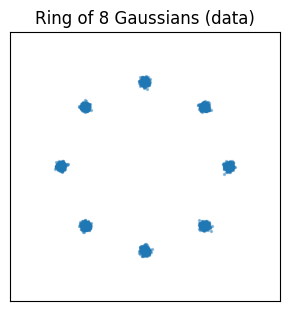

ring_stats on real data: {'modes_covered': 8, 'frac_good': 0.999666690826416}


In [2]:
RING_K, RING_R, RING_S = 8, 2.0, 0.05
RING_CENTERS = torch.stack([RING_R * torch.cos(2 * math.pi * torch.arange(RING_K) / RING_K),
                            RING_R * torch.sin(2 * math.pi * torch.arange(RING_K) / RING_K)], dim=1)

def sample_ring(n, generator=None):
    which = torch.randint(0, RING_K, (n,), generator=generator)
    return RING_CENTERS[which] + RING_S * torch.randn(n, 2, generator=generator)

def ring_stats(x, threshold=0.2):
    # A sample is "good" if it lands within `threshold` of a cluster center (4 cluster std devs).
    # A mode is "covered" if it gets at least 1% of the samples it would get under the true distribution.
    dist, nearest = torch.cdist(x, RING_CENTERS).min(dim=1)
    good = dist < threshold
    counts = torch.bincount(nearest[good], minlength=RING_K)
    return {'modes_covered': int((counts > 0.01 * len(x) / RING_K).sum()), 'frac_good': good.float().mean().item()}

def plot_points(ax, x, title, color='C0'):
    ax.scatter(x[:, 0], x[:, 1], s=2, alpha=0.4, color=color)
    ax.set(xlim=(-3.2, 3.2), ylim=(-3.2, 3.2), aspect='equal', title=title)
    ax.set_xticks([]); ax.set_yticks([])

X_ring = sample_ring(20000, generator=torch.Generator().manual_seed(453))
fig, ax = plt.subplots(figsize=(3.5, 3.5))
plot_points(ax, X_ring[:3000], 'Ring of 8 Gaussians (data)')
plt.show()
print('ring_stats on real data:', ring_stats(X_ring[:3000]))

## Part A: Variational Autoencoders (24 pts)

A VAE has an **encoder** $q_\phi(z \mid x) = \mathcal{N}\big(\mu_\phi(x), \operatorname{diag}(\sigma^2_\phi(x))\big)$, a **decoder** $p_\theta(x \mid z)$, and a **prior** $p(z) = \mathcal{N}(0, I)$. It is trained by maximizing the evidence lower bound (ELBO):

$$\log p_\theta(x) \;\ge\; \underbrace{\mathbb{E}_{q_\phi(z\mid x)}\big[\log p_\theta(x \mid z)\big]}_{\text{reconstruction}} \;-\; \underbrace{\mathrm{KL}\big(q_\phi(z \mid x)\,\big\|\,p(z)\big)}_{\text{regularizer}}$$

The bound holds for *any* encoder, because the gap is $\log p_\theta(x) - \text{ELBO} = \mathrm{KL}\big(q_\phi(z\mid x)\,\|\,p_\theta(z\mid x)\big) \ge 0$. The encoder outputs $\log\sigma^2$ (`logvar`) rather than $\sigma$, so it never has to produce a positive number directly.

### A.1) Reparameterization and the KL term (10 pts)

Complete:
- `reparameterize(mu, logvar)`: return $z = \mu + \sigma \odot \varepsilon$ with $\varepsilon \sim \mathcal{N}(0, I)$ and $\sigma = \exp(\tfrac12 \log\sigma^2)$. Written this way, $z$ is a differentiable function of $\mu$ and $\sigma$, so gradients reach the encoder.
- `kl_to_standard_normal(mu, logvar)`: the closed-form KL from the encoder's Gaussian to the prior, summed over latent dimensions (one number per example, shape `(batch,)`):
$$\mathrm{KL}\big(\mathcal{N}(\mu, \operatorname{diag}(\sigma^2))\,\big\|\,\mathcal{N}(0, I)\big) = \sum_{j} \tfrac12\left(\mu_j^2 + \sigma_j^2 - 1 - \log\sigma_j^2\right).$$

In [7]:
def reparameterize(mu, logvar):
    std = torch.exp(0.5 * logvar)
    eps = torch.randn_like(std)
    return mu + std * eps

def kl_to_standard_normal(mu, logvar):
    return 0.5 * torch.sum(mu.pow(2) + logvar.exp() - 1 - logvar, dim=1)

In [11]:
from torch.distributions import Normal, Bernoulli, kl_divergence

torch.manual_seed(0)
mu, logvar = torch.randn(5, 3), torch.randn(5, 3)
ref = kl_divergence(Normal(mu, torch.exp(0.5 * logvar)), Normal(0.0, 1.0)).sum(dim=1)
assert kl_to_standard_normal(mu, logvar).shape == (5,), "KL should return one value per example"
assert torch.allclose(kl_to_standard_normal(mu, logvar), ref, atol=1e-5), "KL doesn't match torch.distributions"

mu = torch.tensor([1.0, -2.0], requires_grad=True)
logvar = torch.log(torch.tensor([4.0, 0.25])).requires_grad_(True)
z = reparameterize(mu.expand(200000, 2), logvar.expand(200000, 2))
assert torch.allclose(z.mean(dim=0), mu.detach(), atol=0.03), "samples have the wrong mean"
assert torch.allclose(z.std(dim=0), torch.tensor([2.0, 0.5]), rtol=0.02), "samples have the wrong std"
z.sum().backward()
assert mu.grad is not None and logvar.grad is not None and logvar.grad.abs().sum() > 0, \
    "gradients should flow back to mu and logvar"
print('looks good!')

looks good!


### A.2) The VAE loss (8 pts)

Each pixel is a Bernoulli variable whose **logit** is the decoder's output, so $-\log p_\theta(x \mid z)$ is the binary cross-entropy **summed over the 784 pixels**. Complete `vae_loss()`, the negative ELBO averaged over the batch, with one sample of $z$ per example:

$$\text{loss} = \frac{1}{B}\sum_{i=1}^{B}\Big[\underbrace{\textstyle\sum_{j=1}^{784} \mathrm{BCE}(\text{logit}_{ij}, x_{ij})}_{\texttt{rec}} \;+\; \beta\cdot \underbrace{\mathrm{KL}\big(q(z\mid x_i)\,\|\,p(z)\big)}_{\texttt{kl}}\Big]$$

$\beta = 1$ is the true ELBO; A.3 and A.4 vary $\beta$. Return `rec` and `kl` as batch averages too, for logging. *(Hint: `F.binary_cross_entropy_with_logits(..., reduction='none')`.)*

In [15]:
def vae_loss(logits, x, mu, logvar, beta=1.0):
    rec = F.binary_cross_entropy_with_logits(logits, x, reduction='none')
    rec = rec.view(rec.size(0), -1).sum(dim=1).mean()
    kl = kl_to_standard_normal(mu, logvar).mean()
    return rec + beta * kl, rec, kl

In [16]:

torch.manual_seed(0)
logits, x = torch.randn(4, 784), torch.rand(4, 784).round()
mu, logvar = torch.randn(4, 2), torch.randn(4, 2)
loss, rec, kl = vae_loss(logits, x, mu, logvar, beta=2.0)
ref_rec = -Bernoulli(logits=logits).log_prob(x).sum(dim=1).mean()
ref_kl = kl_divergence(Normal(mu, torch.exp(0.5 * logvar)), Normal(0.0, 1.0)).sum(dim=1).mean()
assert torch.allclose(rec, ref_rec, atol=1e-3), "rec should be BCE summed over pixels, averaged over the batch"
assert torch.allclose(kl, ref_kl, atol=1e-4), "kl should be averaged over the batch"
assert torch.allclose(loss, ref_rec + 2.0 * ref_kl, atol=1e-3), "loss should be rec + beta * kl"
print('looks good!')

looks good!


### A.3) Train two VAEs: with and without the KL term

**No modification required.** This trains two VAEs with a **2D** latent space, using *your* functions (about 30 seconds): one with $\beta = 1$ and one with $\beta = 0$ (no KL term). For each it shows the encoder means $\mu(x)$ of test digits with the prior's $\pm 2$ circle, reconstructions (top: original), and **new samples** decoded from $z \sim \mathcal{N}(0, I)$.

beta = 1: test rec = 140.7, test KL = 6.05, std of mu over the data = 1.06, average encoder sigma = 0.0585
beta = 0: test rec = 139.2, test KL = 27.20, std of mu over the data = 3.33, average encoder sigma = 0.0019


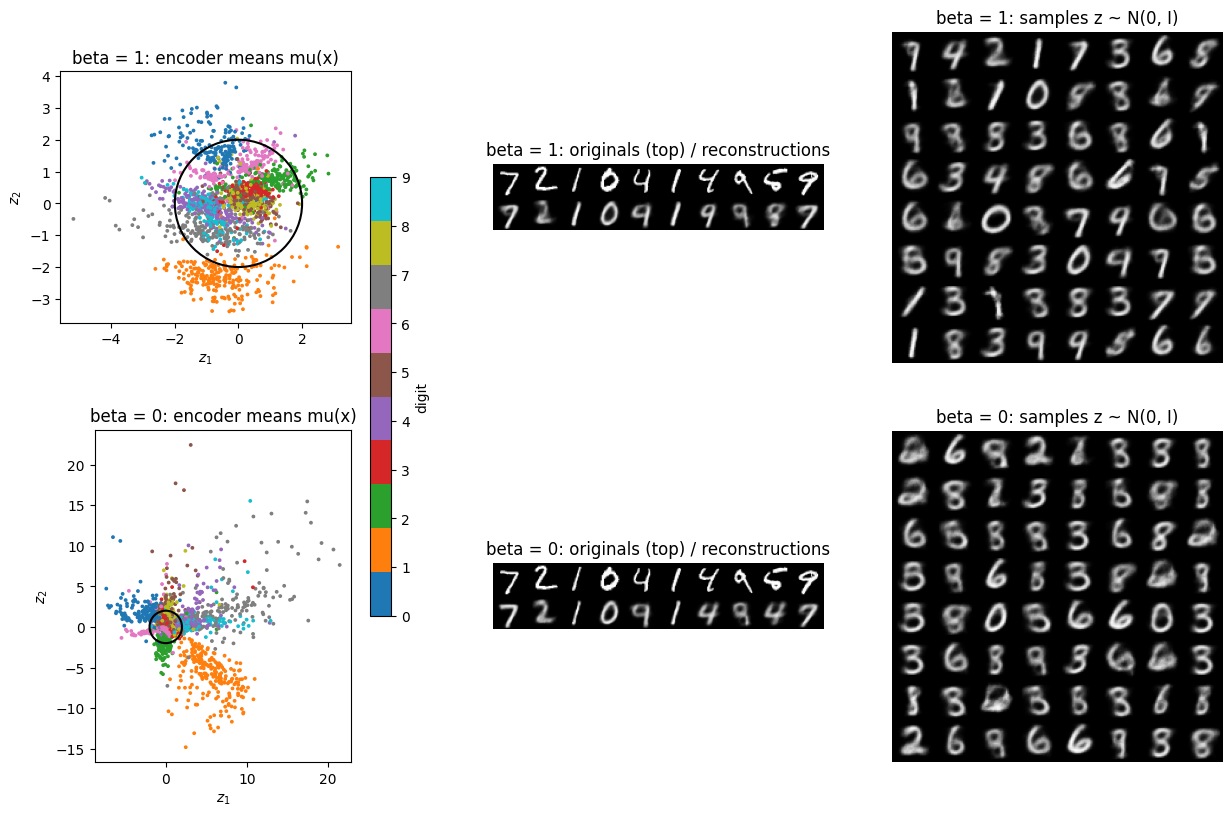

In [17]:
class VAE(nn.Module):
    def __init__(self, z_dim=2, hidden=512):
        super().__init__()
        self.encoder = nn.Sequential(nn.Linear(784, hidden), nn.ReLU(), nn.Linear(hidden, hidden), nn.ReLU())
        self.fc_mu = nn.Linear(hidden, z_dim)
        self.fc_logvar = nn.Linear(hidden, z_dim)
        self.decoder = nn.Sequential(nn.Linear(z_dim, hidden), nn.ReLU(), nn.Linear(hidden, hidden), nn.ReLU(),
                                     nn.Linear(hidden, 784))

    def encode(self, x):
        h = self.encoder(x)
        return self.fc_mu(h), self.fc_logvar(h)

    def forward(self, x):
        mu, logvar = self.encode(x)
        z = reparameterize(mu, logvar)
        return self.decoder(z), mu, logvar

def train_vae(beta, epochs=15, batch_size=128, lr=1e-3):
    torch.manual_seed(453)
    model = VAE()
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    g = torch.Generator().manual_seed(453)
    for _ in range(epochs):
        idx = torch.randperm(len(X_mnist), generator=g)
        for start in range(0, len(X_mnist), batch_size):
            x = X_mnist[idx[start:start + batch_size]]
            logits, mu, logvar = model(x)
            loss, rec, kl = vae_loss(logits, x, mu, logvar, beta=beta)
            opt.zero_grad()
            loss.backward()
            opt.step()
    return model

def montage(images, nrow):
    # images: (n, 784) in [0, 1] -> one (nrow*28, ncol*28) array
    n = images.shape[0]
    ncol = math.ceil(n / nrow)
    grid = torch.ones(nrow * 28, ncol * 28)
    for i in range(n):
        r, c = divmod(i, ncol)
        grid[r * 28:(r + 1) * 28, c * 28:(c + 1) * 28] = images[i].view(28, 28)
    return grid

vaes = {beta: train_vae(beta) for beta in [1.0, 0.0]}

fig, axes = plt.subplots(2, 3, figsize=(15, 9.5), gridspec_kw={'width_ratios': [1.1, 1, 1]})
for row, (beta, model) in enumerate(vaes.items()):
    model.eval()
    with torch.no_grad():
        logits, mu, logvar = model(X_mnist_test)
        _, rec, kl = vae_loss(logits, X_mnist_test, mu, logvar)
        recon = torch.sigmoid(model.decoder(mu[:10]))
        prior_samples = torch.sigmoid(model.decoder(torch.randn(64, 2, generator=torch.Generator().manual_seed(0))))
    sc = axes[row, 0].scatter(mu[:, 0], mu[:, 1], c=y_mnist_test, cmap='tab10', s=3)
    axes[row, 0].add_patch(plt.Circle((0, 0), 2, fill=False, color='k', lw=1.5))
    axes[row, 0].set(title=f'beta = {beta:g}: encoder means mu(x)', xlabel='$z_1$', ylabel='$z_2$', aspect='equal')
    axes[row, 1].imshow(montage(torch.cat([X_mnist_test[:10], recon]), nrow=2), cmap='gray')
    axes[row, 1].set_title(f'beta = {beta:g}: originals (top) / reconstructions')
    axes[row, 2].imshow(montage(prior_samples, nrow=8), cmap='gray')
    axes[row, 2].set_title(f'beta = {beta:g}: samples z ~ N(0, I)')
    for ax in axes[row, 1:]:
        ax.axis('off')
    print(f'beta = {beta:g}: test rec = {rec:.1f}, test KL = {kl:.2f}, '
          f'std of mu over the data = {mu.std(dim=0).mean():.2f}, '
          f'average encoder sigma = {torch.exp(0.5 * logvar).mean():.4f}')
fig.colorbar(sc, ax=axes[:, 0], shrink=0.6, label='digit')
plt.show()

**What to look for** (not graded). Both models reconstruct well, but only $\beta = 1$ gives good samples. Without the KL term, the encoder spreads its codes far outside the prior and shrinks $\sigma$ to almost zero, so samples from the prior land where the decoder never trained. With $\beta = 1$, the KL term packs the codes into the prior's region, so any $z \sim \mathcal{N}(0, I)$ decodes to a digit.

### A.4) Is the latent being used? Posterior collapse (6 pts)

If the KL term wins completely, $q(z \mid x) \approx p(z)$ for every input: the code carries no information about $x$, and the decoder learns to ignore it. This is **posterior collapse**, and it can hit all latent dimensions or only some. A small KL in the training log is the warning sign. The diagnosis is whether each dimension's encoder mean $\mu_j(x)$ changes with the input. (KL alone can't tell: a dimension that gives every input the same confident code has a large KL but carries no information.)

Complete:
- `kl_per_dim(mu, logvar)`: the A.1 KL for **each latent dimension separately**, averaged over the batch; shape `(z_dim,)`.
- `active_units(mu, threshold=0.01)`: the number of dimensions whose $\mu_j$ has variance over the batch greater than `threshold`, as a Python `int`.

In [ ]:
def kl_per_dim(mu, logvar):
    return # <your code>

def active_units(mu, threshold=0.01):
    return # <your code>

In [ ]:
torch.manual_seed(0)
mu, logvar = torch.randn(50, 4), torch.randn(50, 4)
assert kl_per_dim(mu, logvar).shape == (4,), "return one value per latent dimension"
assert torch.allclose(kl_per_dim(mu, logvar).sum(), kl_to_standard_normal(mu, logvar).mean(), atol=1e-5), \
    "summed over dimensions, kl_per_dim should match the batch average of kl_to_standard_normal"

# Dimension 0 encodes the input; dimension 1 has collapsed to the prior (mu = 0, sigma = 1 for every input);
# dimension 2 has a confident but constant code (sigma small, mu the same for every input): large KL, yet no information about x.
mu = torch.stack([torch.linspace(-2, 2, 100), torch.zeros(100), torch.full((100,), 0.5)], dim=1)
logvar = torch.stack([torch.full((100,), -3.0), torch.zeros(100), torch.full((100,), -3.0)], dim=1)
kd = kl_per_dim(mu, logvar)
assert kd[1].abs() < 1e-6, "a dimension with q(z_j | x) = N(0, 1) for every x has zero KL"
assert kd[0] > 1 and kd[2] > 1
n_active = active_units(mu)
assert isinstance(n_active, int), "return a Python int"
assert n_active == 1, "only dimension 0 changes with the input"
print('looks good!')

**No modification required.** This trains two VAEs with an **8-dimensional** latent space (about 30 seconds): $\beta = 1$ and $\beta = 20$. A large $\beta$ forces collapse; in practice it also happens at $\beta = 1$ when the decoder is powerful (for example, autoregressive). The plots show the training log, your `kl_per_dim` with the number of active units, and reconstructions.

In [ ]:
def train_vae_logged(beta, z_dim=8, epochs=10, batch_size=128, lr=1e-3):
    torch.manual_seed(453)
    model = VAE(z_dim=z_dim)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    g = torch.Generator().manual_seed(453)
    history = []
    for _ in range(epochs):
        idx = torch.randperm(len(X_mnist), generator=g)
        rec_sum = kl_sum = 0.0
        for start in range(0, len(X_mnist), batch_size):
            x = X_mnist[idx[start:start + batch_size]]
            logits, mu, logvar = model(x)
            loss, rec, kl = vae_loss(logits, x, mu, logvar, beta=beta)
            opt.zero_grad()
            loss.backward()
            opt.step()
            rec_sum += rec.item() * len(x)
            kl_sum += kl.item() * len(x)
        history.append((rec_sum / len(X_mnist), kl_sum / len(X_mnist)))
    return model, history

collapse_runs = {beta: train_vae_logged(beta) for beta in [1.0, 20.0]}

fig, axes = plt.subplots(2, 4, figsize=(17, 7.5), gridspec_kw={'width_ratios': [1, 1, 1, 1.6]})
for row, (beta, (model, history)) in enumerate(collapse_runs.items()):
    model.eval()
    with torch.no_grad():
        mu, logvar = model.encode(X_mnist_test)
        recon = torch.sigmoid(model.decoder(mu[:10]))
    epochs = range(1, len(history) + 1)
    axes[row, 0].plot(epochs, [h[0] for h in history], 'o-', color='C0')
    axes[row, 0].set(title=f'beta = {beta:g}: reconstruction term', xlabel='epoch', ylim=(0, 230))
    axes[row, 1].plot(epochs, [h[1] for h in history], 'o-', color='C3')
    axes[row, 1].set(title=f'beta = {beta:g}: KL term', xlabel='epoch', ylim=(0, 18))
    kd = kl_per_dim(mu, logvar)
    axes[row, 2].bar(range(len(kd)), kd, color='C3')
    axes[row, 2].set(title=f'KL per dimension ({active_units(mu)} of {len(kd)} active)', xlabel='latent dimension j',
                     ylim=(0, 2.6))
    axes[row, 3].imshow(montage(torch.cat([X_mnist_test[:10], recon]), nrow=2), cmap='gray')
    axes[row, 3].set_title(f'beta = {beta:g}: originals (top) / reconstructions')
    axes[row, 3].axis('off')
    print(f'beta = {beta:g}: final rec = {history[-1][0]:.1f}, final KL = {history[-1][1]:.2f}, '
          f'active units = {active_units(mu)} of {len(kd)}')
plt.tight_layout()
plt.show()

**What to look for** (not graded). With $\beta = 1$, all 8 dimensions carry KL and the reconstructions match the inputs. With $\beta = 20$, the KL drops to almost 0 in the first epoch while the reconstruction term stalls far above the $\beta = 1$ run. Nearly every dimension has $q(z_j \mid x) = \mathcal{N}(0, 1)$ for every input, so the decoder outputs nearly the same blurry digit for everything. Read the KL next to the reconstruction term: a KL near 0 plus a stalled reconstruction means the latent space is switched off.

## Part B: Diffusion Models (30 pts)

A diffusion model (here DDPM; Ho, Jain & Abbeel, 2020) fixes a **forward process** that adds Gaussian noise over $T$ steps,

$$q(x_t \mid x_{t-1}) = \mathcal{N}\big(\sqrt{\alpha_t}\, x_{t-1},\; \beta_t I\big), \qquad \alpha_t = 1 - \beta_t,$$

until $x_T$ is almost pure $\mathcal{N}(0, I)$ noise. A network $\hat\varepsilon_\theta(x_t, t)$ learns to undo it. Sampling starts from noise and runs the learned reverse process.

**Indexing:** the math uses $t = 1, \dots, T$. In code, index `t = 0, ..., T-1` stands for step $t+1$, so `alpha_bars[t]` is $\bar\alpha_{t+1}$. Just use the arrays consistently.

### B.1) Noise schedule and the forward process in closed form (8 pts)

Let $\bar\alpha_t = \prod_{s=1}^{t} \alpha_s$. The forward process has a closed form, so $x_t$ takes one line instead of $t$ noising steps:

$$x_t = \sqrt{\bar\alpha_t}\, x_0 + \sqrt{1-\bar\alpha_t}\;\varepsilon, \quad \varepsilon \sim \mathcal{N}(0, I), \qquad\text{i.e.}\qquad q(x_t \mid x_0) = \mathcal{N}\big(\sqrt{\bar\alpha_t}\, x_0,\; (1-\bar\alpha_t)\, I\big).$$

Complete the schedule and `q_sample()`. Use $T = 100$, `betas` evenly spaced from `1e-4` to `0.1` (`torch.linspace`), `alphas`, and their cumulative product `alpha_bars` (`torch.cumprod`). `q_sample(x0, t, eps)` takes `x0` and `eps` of shape `(n, 2)` and integer timesteps `t` of shape `(n,)`. *(Hint: `alpha_bars[t][:, None]` broadcasts against `(n, 2)`.)*

In [ ]:
T = 100
betas = # <your code>
alphas = # <your code>
alpha_bars = # <your code>

def q_sample(x0, t, eps):
    ab = # <your code>
    return # <your code>

The self-check compares your `q_sample` with running the forward process step by step (`forward_chain`, given below). The two should give the same distribution.

In [ ]:
def forward_chain(x0, n_steps, generator):
    x = x0.clone()
    for t in range(n_steps):
        x = torch.sqrt(alphas[t]) * x + torch.sqrt(betas[t]) * torch.randn(x.shape, generator=generator)
    return x

assert betas.shape == (T,) and abs(betas[0].item() - 1e-4) < 1e-8 and abs(betas[-1].item() - 0.1) < 1e-6, "check betas"
g = torch.Generator().manual_seed(0)
x0 = torch.tensor([[1.5, -0.5]]).repeat(50000, 1)
for n_steps in [1, 10, 40]:
    chain = forward_chain(x0, n_steps, g)
    t = torch.full((50000,), n_steps - 1, dtype=torch.long)       # n_steps steps done = Python index n_steps-1
    shot = q_sample(x0, t, torch.randn(x0.shape, generator=g))
    assert torch.allclose(chain.mean(0), shot.mean(0), atol=0.02), f"means differ after {n_steps} steps"
    assert torch.allclose(chain.std(0), shot.std(0), atol=0.02), f"stds differ after {n_steps} steps"
assert alpha_bars[-1] < 0.01, "after T steps almost no signal should remain"
print('looks good!')

In [ ]:
fig, axes = plt.subplots(1, 6, figsize=(16, 3))
x0 = X_ring[:3000]
for ax, t in zip(axes, [0, 5, 15, 30, 60, 99]):
    xt = q_sample(x0, torch.full((len(x0),), t, dtype=torch.long), torch.randn_like(x0))
    plot_points(ax, xt, f't = {t}   (alpha_bar = {alpha_bars[t]:.3f})')
plt.suptitle('Forward process: the ring dissolves into N(0, I)', y=1.03)
plt.show()

### B.2) The training loss (6 pts)

DDPM trains the network to predict the added noise. Complete `diffusion_loss(model, x0)`:

1. draw a timestep `t` uniformly from `{0, ..., T-1}` for each example (`torch.randint`),
2. draw noise `eps` from $\mathcal{N}(0, I)$, the same shape as `x0`,
3. make `xt` with your `q_sample`,
4. return the mean squared error between `model(xt, t)` and `eps`.

In [ ]:
def diffusion_loss(model, x0):
    t = # <your code>
    eps = # <your code>
    xt = # <your code>
    return # <your code>

In [ ]:
class ZeroModel(nn.Module):
    def forward(self, x, t):
        return torch.zeros_like(x)

torch.manual_seed(0)
loss = diffusion_loss(ZeroModel(), X_ring[:20000])
assert loss.dim() == 0, "the loss should be a scalar"
assert abs(loss.item() - 1.0) < 0.03, "predicting 0 should give a loss of about E[eps^2] = 1"

class SpyModel(nn.Module):
    def forward(self, x, t):
        self.t = t
        return torch.zeros_like(x)

spy = SpyModel()
diffusion_loss(spy, X_ring[:20000])
assert spy.t.min() == 0 and spy.t.max() == T - 1 and spy.t.dtype == torch.long, "t should be integers in 0..T-1"
print('looks good!')

**No modification required.** A small MLP denoiser, which also receives the timestep through a learned embedding, is trained with your `diffusion_loss` (about 10 seconds).

In [ ]:
class Denoiser(nn.Module):
    def __init__(self, hidden=128):
        super().__init__()
        self.t_embed = nn.Embedding(T, hidden)
        self.inp = nn.Linear(2, hidden)
        self.net = nn.Sequential(nn.ReLU(), nn.Linear(hidden, hidden), nn.ReLU(),
                                 nn.Linear(hidden, hidden), nn.ReLU(), nn.Linear(hidden, 2))

    def forward(self, x, t):
        return self.net(self.inp(x) + self.t_embed(t))

torch.manual_seed(453)
denoiser = Denoiser()
opt = torch.optim.Adam(denoiser.parameters(), lr=1e-3)
g = torch.Generator().manual_seed(453)
losses = []
for step in range(6000):
    x0 = X_ring[torch.randint(0, len(X_ring), (256,), generator=g)]
    loss = diffusion_loss(denoiser, x0)
    opt.zero_grad()
    loss.backward()
    opt.step()
    losses.append(loss.item())

plt.figure(figsize=(6, 3))
plt.plot(torch.tensor(losses).view(-1, 50).mean(dim=1))
plt.xlabel('Step (x50)'); plt.ylabel('Noise-prediction MSE')
plt.show()

### B.3) Sampling: running the process backwards (10 pts)

Complete `p_sample_loop()`, the DDPM sampler. Start from $x \sim \mathcal{N}(0, I)$, then for `t = T-1, ..., 0`:

$$\mu_t = \frac{1}{\sqrt{\alpha_t}}\left(x - \frac{\beta_t}{\sqrt{1-\bar\alpha_t}}\;\hat\varepsilon_\theta(x, t)\right), \qquad x \leftarrow \begin{cases}\mu_t + \sqrt{\beta_t}\; z,\;\; z \sim \mathcal{N}(0, I) & \text{if } t > 0\\[2pt] \mu_t & \text{if } t = 0.\end{cases}$$

In words: remove the predicted noise, rescale, and add back a little fresh noise, except at the last step. Draw random numbers with `generator=generator` (for example `torch.randn(n, 2, generator=generator)`).

In [ ]:
@torch.no_grad()
def p_sample_loop(model, n, generator=None):
    x = torch.randn(n, 2, generator=generator)
    snapshots = {T: x.clone()}
    for t in reversed(range(T)):
        eps_hat = model(x, torch.full((n,), t, dtype=torch.long))
        mean = # <your code>
        if t > 0:
            x = # <your code>
        else:
            x = # <your code>
        snapshots[t] = x.clone()
    return x, snapshots

The self-check uses fake denoisers that always predict the same constant, for which the samples' mean and variance can be computed exactly.

In [ ]:
class ConstModel(nn.Module):
    def __init__(self, c):
        super().__init__()
        self.c = c
    def forward(self, x, t):
        return torch.full_like(x, self.c)

for c in [0.0, 0.3]:
    m, v = 0.0, 1.0
    for t in reversed(range(T)):
        m = (m - betas[t] / torch.sqrt(1 - alpha_bars[t]) * c) / torch.sqrt(alphas[t])
        v = v / alphas[t] + (betas[t] if t > 0 else 0.0)
    out, snaps = p_sample_loop(ConstModel(c), 40000, generator=torch.Generator().manual_seed(1))
    assert len(snaps) == T + 1, "there should be a snapshot for every step"
    assert abs(out.mean().item() - float(m)) < 0.02 * math.sqrt(float(v)) + 1e-6, f"sample mean is off (c={c})"
    assert abs(out.var().item() / float(v) - 1) < 0.03, f"sample variance is off (c={c})"
print('looks good!')

In [ ]:
diff_samples, snaps = p_sample_loop(denoiser, 3000, generator=torch.Generator().manual_seed(0))
fig, axes = plt.subplots(1, 6, figsize=(16, 3))
for ax, t in zip(axes, [100, 60, 30, 15, 5, 0]):
    plot_points(ax, snaps[t], f'after reaching t = {t}', color='C2')
plt.suptitle('Reverse process: noise becomes data', y=1.03)
plt.show()
print('diffusion samples:', ring_stats(diff_samples))

### B.4) From predicted noise to a clean estimate (6 pts)

Solving the closed form for $x_0$, with the *predicted* noise in place of the true noise, gives the model's estimate of the clean point that $x_t$ came from:

$$\hat x_0 = \frac{x_t - \sqrt{1-\bar\alpha_t}\;\hat\varepsilon_\theta(x_t, t)}{\sqrt{\bar\alpha_t}}.$$

Complete `predict_x0(model, xt, t)` (same shapes and indexing as `q_sample`). The self-check first gives it the true noise, so it must recover $x_0$ exactly, then checks that your trained denoiser's estimates land near the ring.

In [ ]:
def predict_x0(model, xt, t):
    ab = # <your code>
    eps_hat = # <your code>
    return # <your code>

In [ ]:
class OracleModel(nn.Module):
    def __init__(self, eps):
        super().__init__()
        self.eps = eps
    def forward(self, x, t):
        return self.eps

g = torch.Generator().manual_seed(0)
x0 = sample_ring(1000, generator=g)
t = torch.randint(0, T, (1000,), generator=g)
eps = torch.randn(1000, 2, generator=g)
assert torch.allclose(predict_x0(OracleModel(eps), q_sample(x0, t, eps), t), x0, atol=1e-3), \
    "with the true noise, predict_x0 should recover x0 exactly"

t = torch.full((2000,), 10, dtype=torch.long)
xt = q_sample(sample_ring(2000, generator=g), t, torch.randn(2000, 2, generator=g))
with torch.no_grad():
    x0_hat = predict_x0(denoiser, xt, t)
noisy, denoised = ring_stats(xt)['frac_good'], ring_stats(x0_hat)['frac_good']
print(f'fraction of points near a cluster at t = 10: noisy x_t {noisy:.2f} -> predicted x0 {denoised:.2f}')
assert denoised > noisy + 0.1, "the trained denoiser's x0 estimates should land closer to the clusters than x_t does"
print('looks good!')

**No modification required.** This plots the trained denoiser's vector field $-\hat\varepsilon_\theta(x, t)/\sqrt{1-\bar\alpha_t}$ at a small noise level. Arrow lengths are normalized; color shows magnitude.

In [ ]:
t_show = 5
grid = torch.stack(torch.meshgrid(torch.linspace(-3, 3, 25), torch.linspace(-3, 3, 25), indexing='xy'), dim=-1).view(-1, 2)
with torch.no_grad():
    field = -denoiser(grid, torch.full((len(grid),), t_show, dtype=torch.long)) / torch.sqrt(1 - alpha_bars[t_show])
mag = field.norm(dim=1, keepdim=True)
fig, ax = plt.subplots(figsize=(5.5, 5.5))
ax.scatter(X_ring[:2000, 0], X_ring[:2000, 1], s=2, alpha=0.3, color='gray')
q = ax.quiver(grid[:, 0], grid[:, 1], (field / mag)[:, 0], (field / mag)[:, 1], mag.squeeze().log(), cmap='viridis')
ax.set(aspect='equal', title=f'$-\\hat\\epsilon(x, t)/\\sqrt{{1-\\bar\\alpha_t}}$ at t = {t_show}')
plt.colorbar(q, ax=ax, shrink=0.75, label='log magnitude')
plt.show()

**What to look for** (not graded). Every arrow points toward the nearest cluster, and the magnitude shrinks to about zero at the centers: moving along $-\hat\varepsilon$ moves a point toward $\hat x_0$. This field estimates the **score** $\nabla_x \log q_t(x)$, and each sampling step follows it a little. The price is cost: 100 network evaluations per sample here, versus one decoder pass for a VAE.

## Part C: Generative Adversarial Networks (16 pts)

A GAN trains a generator $G(z)$ and a discriminator $D(x) = \sigma(\ell(x))$, where $\ell$ is the discriminator's **logit**, by playing the minimax game

$$\min_G \max_D \; \mathbb{E}_{x\sim p_{\text{data}}}\big[\log D(x)\big] + \mathbb{E}_{z\sim p(z)}\big[\log\big(1 - D(G(z))\big)\big].$$

In practice the generator usually minimizes $-\log D(G(z))$ (the **non-saturating** loss) instead of the original $\log(1 - D(G(z)))$ (the **saturating** loss). In this part you'll see why.

### C.1) GAN losses (6 pts)

Complete the three losses. Each takes discriminator **logits** and returns a scalar averaged over the batch. Use `F.binary_cross_entropy_with_logits`, which is numerically stable: $\mathrm{BCE}(\ell, 1) = -\log\sigma(\ell)$ and $\mathrm{BCE}(\ell, 0) = -\log(1 - \sigma(\ell))$.

- `d_loss(real_logits, fake_logits)`: the discriminator minimizes $-\mathbb{E}[\log D(x)] - \mathbb{E}[\log(1 - D(G(z)))]$.
- `g_loss_saturating(fake_logits)`: the generator minimizes $\mathbb{E}[\log(1 - D(G(z)))]$.
- `g_loss_nonsaturating(fake_logits)`: the generator minimizes $-\mathbb{E}[\log D(G(z))]$.

In [ ]:
def d_loss(real_logits, fake_logits):
    return # <your code>

def g_loss_saturating(fake_logits):
    return # <your code>

def g_loss_nonsaturating(fake_logits):
    return # <your code>

In [ ]:
real_l, fake_l = torch.tensor([[2.0], [0.5]]), torch.tensor([[-1.0], [0.0]])
D_real, D_fake = torch.sigmoid(real_l), torch.sigmoid(fake_l)
assert torch.allclose(d_loss(real_l, fake_l), -(torch.log(D_real).mean() + torch.log(1 - D_fake).mean()), atol=1e-6)
assert torch.allclose(g_loss_saturating(fake_l), torch.log(1 - D_fake).mean(), atol=1e-6)
assert torch.allclose(g_loss_nonsaturating(fake_l), -torch.log(D_fake).mean(), atol=1e-6)
assert torch.isfinite(g_loss_nonsaturating(torch.tensor([[-200.0]]))), "use the logits version for numerical stability"
print('looks good!')

### C.2) The optimal discriminator (5 pts)

Hold the generator fixed, so it defines a distribution $p_g$. The discriminator maximizes

$$V(D, G) = \sum_x \Big[p_{\text{data}}(x)\log D(x) + p_g(x)\log\big(1 - D(x)\big)\Big].$$

$D(x)$ can be chosen separately at each $x$, and maximizing $a \log y + b \log(1-y)$ over $y$ gives $y = a/(a+b)$, so

$$D^*(x) = \frac{p_{\text{data}}(x)}{p_{\text{data}}(x) + p_g(x)}.$$

Here $x$ takes a few discrete values, and each distribution is a tensor of probabilities with $p_{\text{data}}(x) > 0$. The self-check also tries a generator with $p_g(x) = 0$ at some $x$. Complete:
- `optimal_discriminator(p_data, p_g)`: $D^*(x)$ at every $x$.
- `value_at_optimal_D(p_data, p_g)`: $V(D^*, G)$, as a scalar tensor.

In [ ]:
def optimal_discriminator(p_data, p_g):
    return # <your code>

def value_at_optimal_D(p_data, p_g):
    D = # <your code>
    return # <your code>

In [ ]:
p_data = torch.tensor([0.30, 0.25, 0.20, 0.15, 0.07, 0.03], dtype=torch.float64)
p_g = torch.tensor([0.05, 0.10, 0.15, 0.20, 0.25, 0.25], dtype=torch.float64)

# D* beats every other discriminator: check against a fine grid of values of D(x) at each x.
D_star = optimal_discriminator(p_data, p_g)
assert D_star.shape == p_data.shape
y = torch.linspace(1e-4, 1 - 1e-4, 100001, dtype=torch.float64)[:, None]
grid_best = y[torch.argmax(p_data * torch.log(y) + p_g * torch.log(1 - y), dim=0), 0]
assert torch.allclose(D_star, grid_best, atol=1e-4), "D* should maximize the objective at every x"

# A perfect generator: the best discriminator can do no better than a coin flip.
assert torch.allclose(optimal_discriminator(p_data, p_data), torch.full((6,), 0.5, dtype=torch.float64))

# Mode collapse: the data has two modes (x = 0, 1 and x = 2, 3), and the generator covers only the first.
p_two_modes = torch.tensor([0.25, 0.25, 0.25, 0.25], dtype=torch.float64)
p_one_mode = torch.tensor([0.50, 0.50, 0.00, 0.00], dtype=torch.float64)
assert torch.allclose(optimal_discriminator(p_two_modes, p_one_mode),
                      torch.tensor([1/3, 1/3, 1.0, 1.0], dtype=torch.float64)), \
    "under mode collapse, D* should be 1/3 on the covered mode and 1 on the missed one"

# With the discriminator at its best, the game's value is -log 4 + 2 * JS(p_data, p_g) (JS = Jensen-Shannon divergence).
def kl(p, q):
    return (p * torch.log(p / q)).sum()
m = (p_data + p_g) / 2
js = 0.5 * kl(p_data, m) + 0.5 * kl(p_g, m)
V = value_at_optimal_D(p_data, p_g)
assert V.shape == (), "return a scalar"
assert torch.allclose(V, -math.log(4) + 2 * js), "V(D*, G) should equal -log 4 + 2 JS(p_data, p_g)"
assert torch.allclose(value_at_optimal_D(p_data, p_data), torch.tensor(-math.log(4), dtype=torch.float64))
print('looks good!')

**No modification required.** The generator's job is to *minimize* $V(D^*, G)$. This moves $p_g$ in a straight line from a bad guess ($\lambda = 0$) to $p_{\text{data}}$ ($\lambda = 1$) and slightly past, plotting your $V(D^*, G)$.

In [ ]:
lams = torch.linspace(0, 1.1, 111, dtype=torch.float64)    # past 1.1, some probabilities would go negative
values = [value_at_optimal_D(p_data, (1 - lam) * p_g + lam * p_data).item() for lam in lams]
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
axes[0].plot(lams, values, color='C3', lw=2)
axes[0].axhline(-math.log(4), color='gray', ls='--', lw=1)
axes[0].axvline(1.0, color='gray', ls=':', lw=1)
axes[0].set(xlabel='lambda   (p_g = (1 - lambda) * bad guess + lambda * p_data)', ylabel='V(D*, G)',
            title='The game value is lowest exactly when p_g = p_data')
width = 0.38
axes[1].bar(torch.arange(6) - width / 2, p_data, width, label='p_data', color='C0')
axes[1].bar(torch.arange(6) + width / 2, p_g, width, label='p_g (bad guess)', color='C1')
axes[1].plot(torch.arange(6), optimal_discriminator(p_data, p_g), 'ko-', label='D*(x)')
axes[1].set(xlabel='x', title='D* is high where data outnumbers fakes')
axes[1].legend(frameon=False)
plt.tight_layout()
plt.show()
print(f'min V = {min(values):.4f} at lambda = {lams[int(torch.tensor(values).argmin())]:.2f};  -log 4 = {-math.log(4):.4f}')

**What to look for** (not graded). $V(D^*, G) = -\log 4 + 2\,\mathrm{JS}(p_{\text{data}}, p_g)$ (JS is the Jensen-Shannon divergence), which is lowest exactly when $p_g = p_{\text{data}}$, where $D^* = 1/2$ everywhere. The converse also holds: if $D^* = 1/2$ everywhere, the generator has matched the data. Under mode collapse, $D^* = 1$ on the missed mode (no fakes land there) and below $1/2$ on the covered one (too many fakes land there). A GAN never evaluates the likelihood $p_g(x)$. The discriminator learns the density ratio, $D^*/(1 - D^*) = p_{\text{data}}/p_g$, and the generator learns from it.

### C.3) One GAN training step

**No modification required.** GANs alternate one discriminator update and one generator update. Read `gan_step` below; C.4 and C.5 use it. Two details matter. The discriminator's loss uses `fake.detach()`, so its update sends no gradients into the generator. The generator's loss uses the *just-updated* discriminator, and only `opt_G` steps, so only the generator moves.

In [ ]:
def make_mlp_2d(out_dim):
    return nn.Sequential(nn.Linear(2, 128), nn.ReLU(), nn.Linear(128, 128), nn.ReLU(), nn.Linear(128, out_dim))

def gan_step(G, D, opt_G, opt_D, real, g_loss_fn, z):
    fake = G(z)
    loss_D = d_loss(D(real), D(fake.detach()))
    opt_D.zero_grad()
    loss_D.backward()
    opt_D.step()

    loss_G = g_loss_fn(D(fake))
    opt_G.zero_grad()
    loss_G.backward()
    opt_G.step()
    return loss_D.item(), loss_G.item()

### C.4) Train a GAN and compare

**No modification required.** This trains two GANs on the ring with *your* losses (about 30 seconds). To make the generator loss matter, the discriminator first gets a **500-step head start**. We measure the generator's first gradient under each loss, train both for 3,000 steps, and compare with your diffusion samples from B.3.

In [ ]:
def train_gan(g_loss_fn, steps=3000, d_head_start=500, batch_size=256, seed=453):
    torch.manual_seed(seed)
    G, D = make_mlp_2d(2), make_mlp_2d(1)
    opt_G = torch.optim.Adam(G.parameters(), lr=1e-3, betas=(0.5, 0.999))
    opt_D = torch.optim.Adam(D.parameters(), lr=1e-3, betas=(0.5, 0.999))
    g = torch.Generator().manual_seed(seed)
    def real_batch():
        return X_ring[torch.randint(0, len(X_ring), (batch_size,), generator=g)]

    for _ in range(d_head_start):                  # discriminator-only steps
        with torch.no_grad():
            fake = G(torch.randn(batch_size, 2))
        loss = d_loss(D(real_batch()), D(fake))
        opt_D.zero_grad(); loss.backward(); opt_D.step()

    # The generator's gradient before its first update (separate noise, so training is unaffected).
    fake = G(torch.randn(batch_size, 2, generator=torch.Generator().manual_seed(seed + 1)))
    G.zero_grad()
    g_loss_fn(D(fake)).backward()
    first_grad_norm = torch.sqrt(sum((p.grad ** 2).sum() for p in G.parameters())).item()
    first_D_fake = torch.sigmoid(D(fake)).mean().item()

    snapshots = {}
    for step in range(steps + 1):
        gan_step(G, D, opt_G, opt_D, real_batch(), g_loss_fn, torch.randn(batch_size, 2))
        if step in (0, 250, 1000, 3000):
            with torch.no_grad():
                snapshots[step] = G(torch.randn(3000, 2, generator=torch.Generator().manual_seed(0)))
    return G, snapshots, first_grad_norm, first_D_fake

gans = {}
for name, fn in [('non-saturating', g_loss_nonsaturating), ('saturating (minimax)', g_loss_saturating)]:
    G, snapshots, grad_norm, D_fake = train_gan(fn)
    gans[name] = (G, snapshots)
    print(f'{name:22s} first step: mean D(G(z)) = {D_fake:.4f}, ||grad of G|| = {grad_norm:.4f}')

fig, axes = plt.subplots(2, 4, figsize=(14, 7))
for row, (name, (G, snapshots)) in enumerate(gans.items()):
    for col, (step, x) in enumerate(snapshots.items()):
        plot_points(axes[row, col], x, f'{name}\nstep {step}', color='C3')
plt.show()
for name, (G, snapshots) in gans.items():
    print(f'{name:22s} after 3000 steps:', ring_stats(snapshots[3000]))

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(12, 4))
plot_points(axes[0], X_ring[:3000], 'data')
plot_points(axes[1], diff_samples, f'diffusion ({T} network calls / sample)', color='C2')
plot_points(axes[2], gans['non-saturating'][1][3000], 'GAN, non-saturating (1 call / sample)', color='C3')
plt.show()
for name, x in [('diffusion', diff_samples), ('GAN (non-saturating)', gans['non-saturating'][1][3000])]:
    print(f'{name:22s}', ring_stats(x))

**What to look for** (not graded). After the head start, $D(G(z)) \approx 0$. With respect to the logit, the saturating loss $\log(1-\sigma(\ell))$ has derivative $-\sigma(\ell) \approx 0$, while the non-saturating $-\log\sigma(\ell)$ has derivative $-(1-\sigma(\ell)) \approx -1$. So the saturating generator gets almost no gradient exactly when it is worst: about $1/D(G(z))$ times less. Adam partly rescues it, but it ends up worse. The GAN and diffusion both cover all 8 clusters but miss differently: diffusion leaves a halo around each cluster, while the GAN draws thin bridges between them. The GAN needs 1 network call per sample; diffusion needs 100.

### C.5) Reading the loss curves (5 pts)

A GAN's two losses don't fall together like a classifier's, so they're easy to misread. The fix is to translate them back into what the discriminator outputs. With the non-saturating generator loss,

$$L_D = -\overline{\log D(x)} - \overline{\log\big(1 - D(G(z))\big)}, \qquad L_G = -\overline{\log D(G(z))},$$

where bars are batch averages. If the discriminator outputs about $d_{\text{real}}$ on every real example and $d_{\text{fake}}$ on every fake, these are two equations in two unknowns. Complete `implied_D_outputs(loss_D, loss_G)`: return `(d_real, d_fake)` as Python floats. *(Solve the $L_G$ equation first; use `math.exp` and `math.log`.)*

In [ ]:
def implied_D_outputs(loss_D, loss_G):
    d_fake = # <your code>
    d_real = # <your code>
    return d_real, d_fake

In [ ]:
for d_real, d_fake in [(0.9, 0.2), (0.5, 0.5), (0.999, 0.001), (0.6, 0.45)]:
    loss_D = -math.log(d_real) - math.log(1 - d_fake)
    loss_G = -math.log(d_fake)
    out = implied_D_outputs(loss_D, loss_G)
    assert isinstance(out, tuple) and len(out) == 2 and all(isinstance(v, float) for v in out), \
        "return (d_real, d_fake) as Python floats"
    assert math.isclose(out[0], d_real, rel_tol=1e-9) and math.isclose(out[1], d_fake, rel_tol=1e-9), \
        f"expected {(d_real, d_fake)}, got {out}"
d_real, d_fake = implied_D_outputs(2 * math.log(2), math.log(2))
assert math.isclose(d_real, 0.5) and math.isclose(d_fake, 0.5), "L_D = 2 log 2 and L_G = log 2 is a discriminator that can't tell"
print('looks good!')

**No modification required.** This trains two non-saturating GANs for 1,500 steps (about 10 seconds), identical except for the generator's learning rate: **balanced** ($10^{-3}$ for both networks) and **generator too slow** ($10^{-5}$). Top: the logged losses, smoothed; dashed lines mark $L_D = 2\log 2$ and $L_G = \log 2$, where $D = 1/2$ on everything. Bottom: your implied outputs (solid) next to the discriminator's actual averages (dotted).

In [ ]:
def run_logged_gan(lr_G, lr_D=1e-3, steps=1500, batch_size=256, seed=453):
    torch.manual_seed(seed)
    G, D = make_mlp_2d(2), make_mlp_2d(1)
    opt_G = torch.optim.Adam(G.parameters(), lr=lr_G, betas=(0.5, 0.999))
    opt_D = torch.optim.Adam(D.parameters(), lr=lr_D, betas=(0.5, 0.999))
    g = torch.Generator().manual_seed(seed)
    losses, actual = [], []
    for _ in range(steps):
        real = X_ring[torch.randint(0, len(X_ring), (batch_size,), generator=g)]
        losses.append(gan_step(G, D, opt_G, opt_D, real, g_loss_nonsaturating, torch.randn(batch_size, 2)))
        with torch.no_grad():      # the discriminator's actual average outputs, on the same real batch and fresh fakes
            actual.append((torch.sigmoid(D(real)).mean().item(), torch.sigmoid(D(G(torch.randn(batch_size, 2)))).mean().item()))
    return losses, actual

def smooth(v, k=50):
    return F.avg_pool1d(torch.tensor(v, dtype=torch.float32)[None, None], k, stride=1)[0, 0]

runs = {'balanced': run_logged_gan(lr_G=1e-3), 'generator too slow': run_logged_gan(lr_G=1e-5)}

fig, axes = plt.subplots(2, 2, figsize=(13, 7.5))
for col, (name, (losses, actual)) in enumerate(runs.items()):
    LD, LG = smooth([l[0] for l in losses]), smooth([l[1] for l in losses])
    implied = torch.tensor([implied_D_outputs(a, b) for a, b in zip(LD.tolist(), LG.tolist())])
    act_real, act_fake = smooth([a[0] for a in actual]), smooth([a[1] for a in actual])
    steps = range(len(LD))
    ax = axes[0, col]
    ax.plot(steps, LD, color='C0', label='discriminator loss L_D')
    ax.plot(steps, LG, color='C3', label='generator loss L_G')
    ax.axhline(2 * math.log(2), color='C0', ls='--', lw=1)
    ax.axhline(math.log(2), color='C3', ls='--', lw=1)
    ax.set(xlabel='training step', ylim=(0, 9), title=f'{name}: logged losses')
    ax.legend(frameon=False)
    ax = axes[1, col]
    ax.plot(steps, implied[:, 0], color='C0', label='D(x) on real data: implied')
    ax.plot(steps, act_real, color='C0', ls=':', lw=2, label='D(x) on real data: actual average')
    ax.plot(steps, implied[:, 1], color='C3', label='D(G(z)) on fakes: implied')
    ax.plot(steps, act_fake, color='C3', ls=':', lw=2, label='D(G(z)) on fakes: actual average')
    ax.axhline(0.5, color='gray', ls='--', lw=1)
    ax.set(xlabel='training step', ylim=(-0.02, 1.02), title=f'{name}: what the discriminator outputs')
    ax.legend(frameon=False, fontsize=9)
    print(f'{name:19s} last 50 steps: L_D = {LD[-1]:.3f}, L_G = {LG[-1]:.3f} -> implied (D(x), D(G(z))) = '
          f'({implied[-1, 0]:.3f}, {implied[-1, 1]:.3f}); actual = ({act_real[-1]:.3f}, {act_fake[-1]:.3f})')
plt.tight_layout()
plt.show()

**What to look for** (not graded). Balanced: both losses hover near their dashed lines, and the discriminator's outputs stay between about 0.35 and 0.6, so it only partly tells real from fake. That is a healthy GAN. Generator too slow: $L_D$ drops to near 0 while $L_G$ climbs, which means $D(x) \approx 1$ and $D(G(z)) \approx 0$. The discriminator has won, so a falling $L_D$ here means the generator is losing. (The implied values sit below the actual averages because the losses average $\log D$ rather than $D$. The diagnosis is the same.)

Attribution: Ben Lengerich